# Module 7 – Interactive Dashboard Development

## 1. Introduction

RouteRanker is an AI-powered public transportation route optimization project. This module focuses on developing an interactive dashboard using Python and Streamlit to visualize and analyze the results obtained from the previous modules.

## 2. Objectives

- To integrate the outputs of Modules 1 to 6.
- To visualize transportation data using charts and graphs.
- To analyze routes using K-Means and DBSCAN clustering.
- To display Random Forest and XGBoost prediction results.
- To explore hypothetical route optimization scenarios.
- To develop an interactive dashboard using Streamlit.

In [2]:
# Module 7 - Interactive Dashboard Development

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import sys
import warnings

warnings.filterwarnings("ignore")

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [3]:
# Step 9 - Project Directory Setup

from pathlib import Path

# Get the project directory
PROJECT_DIR = Path.cwd().parent

# Define important project folders
DATA_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "dashboard" / "outputs"

# Display folder paths
print("PROJECT DIRECTORY:", PROJECT_DIR)
print("DATA DIRECTORY:", DATA_DIR)
print("MODEL DIRECTORY:", MODEL_DIR)
print("OUTPUT DIRECTORY:", OUTPUT_DIR)

# Check whether folders exist
print("\nFolder Verification:")

print("Project folder:", PROJECT_DIR.exists())
print("Data folder:", DATA_DIR.exists())
print("Models folder:", MODEL_DIR.exists())
print("Output folder:", OUTPUT_DIR.exists())

PROJECT DIRECTORY: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker
DATA DIRECTORY: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed
MODEL DIRECTORY: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\models
OUTPUT DIRECTORY: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\dashboard\outputs

Folder Verification:
Project folder: True
Data folder: True
Models folder: True
Output folder: True


In [4]:
# Step 10 - Load Existing Datasets

DATA_FILES = {
    "main": "module4_processed_dataset.csv",
    "clustering_features": "module5_clustering_features.csv",
    "kmeans": "kmeans_route_clusters.csv",
    "dbscan": "dbscan_cluster_labels.csv",
    "kmeans_inference": "module6_kmeans_inference.csv",
    "classification": "module6_classification_inference.csv",
    "route_analysis": "module6_route_analysis.csv",
    "simulation": "module6_hypothetical_schedule_scenario.csv",
    "comparison": "module6_simulation_comparison.csv"
}

# Load all datasets
datasets = {}

for name, filename in DATA_FILES.items():
    file_path = DATA_DIR / filename

    if file_path.exists():
        datasets[name] = pd.read_csv(file_path)
        print(f"{name}: Loaded successfully")
    else:
        print(f"{name}: File not found - {filename}")

print("\nTotal datasets loaded:", len(datasets))

main: Loaded successfully
clustering_features: Loaded successfully
kmeans: Loaded successfully
dbscan: Loaded successfully
kmeans_inference: Loaded successfully
classification: Loaded successfully
route_analysis: Loaded successfully
simulation: Loaded successfully
comparison: Loaded successfully

Total datasets loaded: 9


In [5]:
# Step 11 - Dataset Overview

dataset_summary = []

for name, df in datasets.items():
    dataset_summary.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

summary_df = pd.DataFrame(dataset_summary)

display(summary_df)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,main,7312,23,0,0
1,clustering_features,7312,15,0,337
2,kmeans,7312,4,0,0
3,dbscan,7312,4,0,0
4,kmeans_inference,7312,4,0,0
5,classification,4721,6,0,0
6,route_analysis,7312,16,0,0
7,simulation,7312,18,0,0
8,comparison,5,4,0,0


In [6]:
# Step 12 - Data Validation

validation_results = []

for name, df in datasets.items():

    errors = []

    # Check empty dataset
    if df.empty:
        errors.append("Empty dataset")

    # Check duplicate column names
    if df.columns.duplicated().any():
        errors.append("Duplicate column names")

    # Check missing values
    missing = df.isnull().sum().sum()

    # Check route identifiers where available
    if "city" in df.columns and "route_id" in df.columns:

        if df[["city", "route_id"]].isnull().any().any():
            errors.append("Missing route identifiers")

        duplicate_keys = df.duplicated(
            subset=["city", "route_id"]
        ).sum()

        if duplicate_keys > 0:
            errors.append(
                f"{duplicate_keys} duplicate city-route keys"
            )

    validation_results.append({
        "Dataset": name,
        "Status": "Passed" if not errors else "Check Required",
        "Missing Values": missing,
        "Issues": "; ".join(errors) if errors else "None"
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

,Dataset,Status,Missing Values,Issues
0,main,Passed,0,None
1,clustering_features,Passed,0,None
2,kmeans,Passed,0,None
3,dbscan,Passed,0,None
4,kmeans_inference,Passed,0,None
5,classification,Passed,0,None
6,route_analysis,Passed,0,None
7,simulation,Passed,0,None
8,comparison,Passed,0,None


City-wise Route Distribution:


city
chennai      4721
hyderabad    1031
ahmedabad     633
mumbai        612
pune          315
Name: route_id, dtype: int64

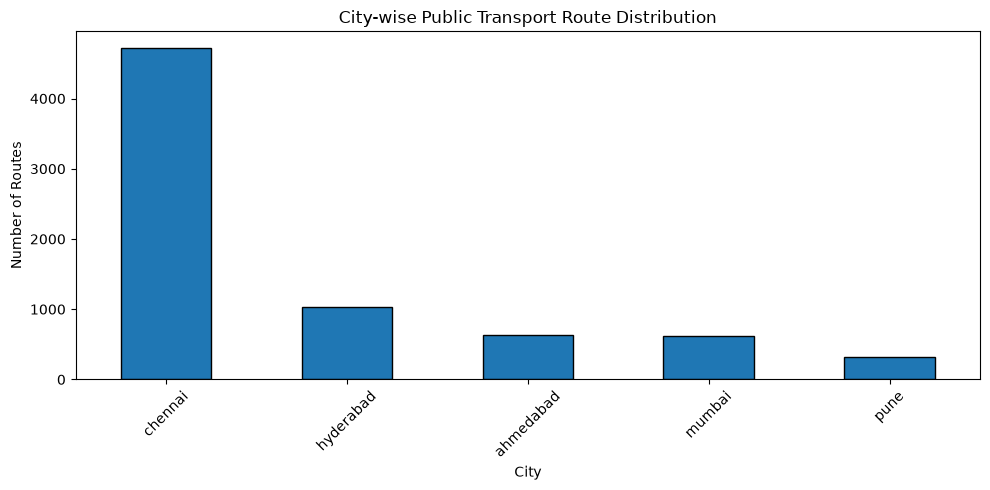

In [7]:
# Step 13 - City-wise Route Distribution

route_df = datasets["route_analysis"].copy()

# Count routes in each city
city_route_count = (
    route_df.groupby("city")["route_id"]
    .count()
    .sort_values(ascending=False)
)

print("City-wise Route Distribution:")
display(city_route_count)

# Visualize route distribution
plt.figure(figsize=(10, 5))

city_route_count.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("City-wise Public Transport Route Distribution")
plt.xlabel("City")
plt.ylabel("Number of Routes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

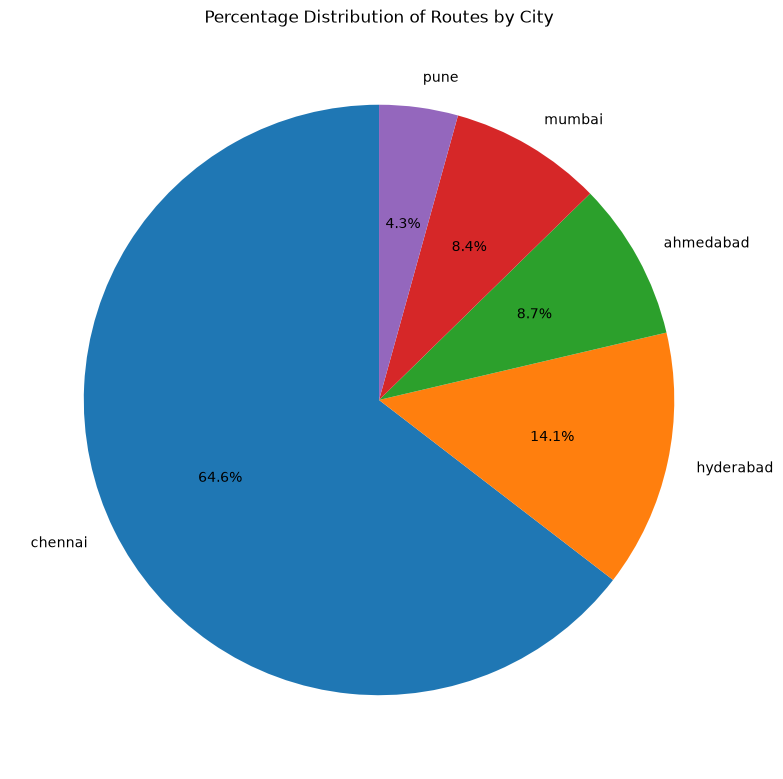

In [8]:
# Step 14 - City-wise Route Percentage

plt.figure(figsize=(8, 8))

city_route_count.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Routes by City")
plt.ylabel("")
plt.tight_layout()
plt.show()

City-wise Scheduled Trip Distribution:


city
mumbai       99080
chennai      48431
hyderabad    44892
ahmedabad    14323
pune         10128
Name: scheduled_trip_count, dtype: int64

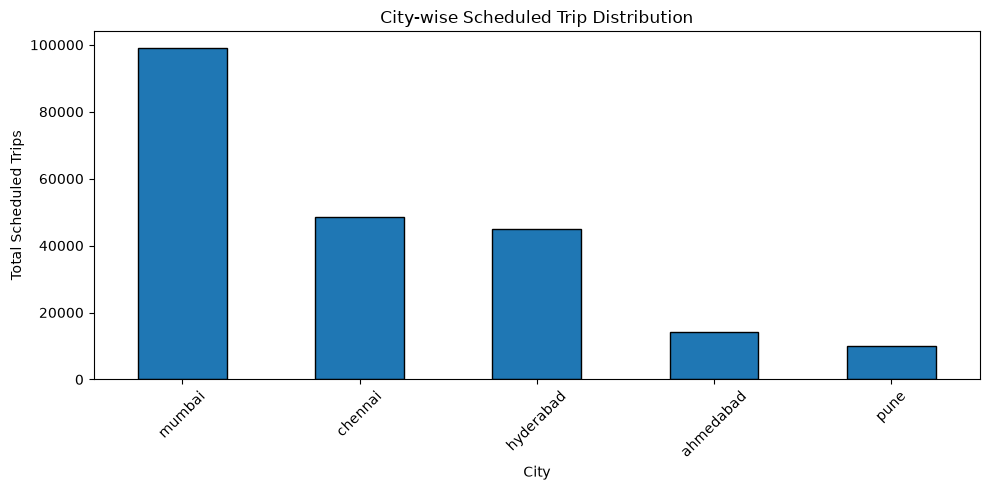

In [9]:
# Step 15 - City-wise Scheduled Trip Analysis

trip_distribution = (
    route_df.groupby("city")["scheduled_trip_count"]
    .sum()
    .sort_values(ascending=False)
)

print("City-wise Scheduled Trip Distribution:")
display(trip_distribution)

# Visualization
plt.figure(figsize=(10, 5))

trip_distribution.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("City-wise Scheduled Trip Distribution")
plt.xlabel("City")
plt.ylabel("Total Scheduled Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Average Scheduled Trips per Route:


city
mumbai       161.90
hyderabad     43.54
pune          32.15
ahmedabad     22.63
chennai       10.26
Name: scheduled_trip_count, dtype: float64

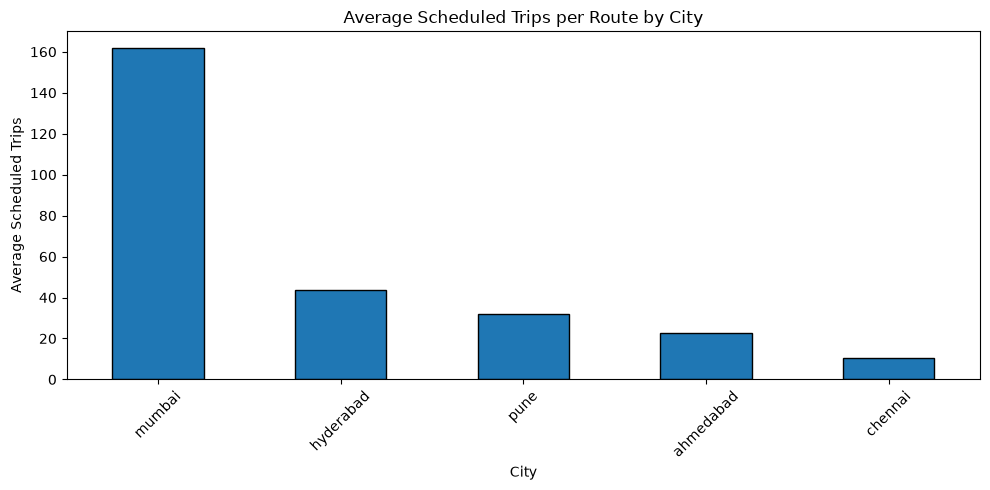

In [10]:
# Step 16 - Average Scheduled Trips per Route

average_trips = (
    route_df.groupby("city")["scheduled_trip_count"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Scheduled Trips per Route:")
display(average_trips.round(2))

# Visualization
plt.figure(figsize=(10, 5))

average_trips.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Scheduled Trips per Route by City")
plt.xlabel("City")
plt.ylabel("Average Scheduled Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
# Step 17 - Route Type Distribution

# Get route type information from the main dataset
main_df = datasets["main"].copy()

print("Available route type information:")
print(main_df.columns.tolist())

# Check whether route_type exists
if "route_type" in main_df.columns:

    route_type_count = main_df["route_type"].value_counts()

    print("\nRoute Type Distribution:")
    display(route_type_count)

    # Visualization
    plt.figure(figsize=(8, 5))

    route_type_count.plot(
        kind="bar",
        edgecolor="black"
    )

    plt.title("Distribution of Public Transport Route Types")
    plt.xlabel("Route Type")
    plt.ylabel("Number of Routes")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

else:
    print("\nThe main dataset does not contain a route_type column.")

Available route type information:
['route_id', 'route_short_name', 'city', 'numeric__scheduled_trip_count', 'numeric__stop_count', 'numeric__estimated_straight_line_route_km', 'numeric__operating_day_count', 'numeric__start_service_hour', 'numeric__end_service_hour', 'numeric__operates_monday', 'numeric__operates_tuesday', 'numeric__operates_wednesday', 'numeric__operates_thursday', 'numeric__operates_friday', 'numeric__operates_saturday', 'numeric__operates_sunday', 'categorical__route_type_1', 'categorical__route_type_3', 'categorical__city_ahmedabad', 'categorical__city_chennai', 'categorical__city_hyderabad', 'categorical__city_mumbai', 'categorical__city_pune']

The main dataset does not contain a route_type column.


Route Type Distribution:


Metro / Subway     787.0
Bus               6525.0
dtype: float64

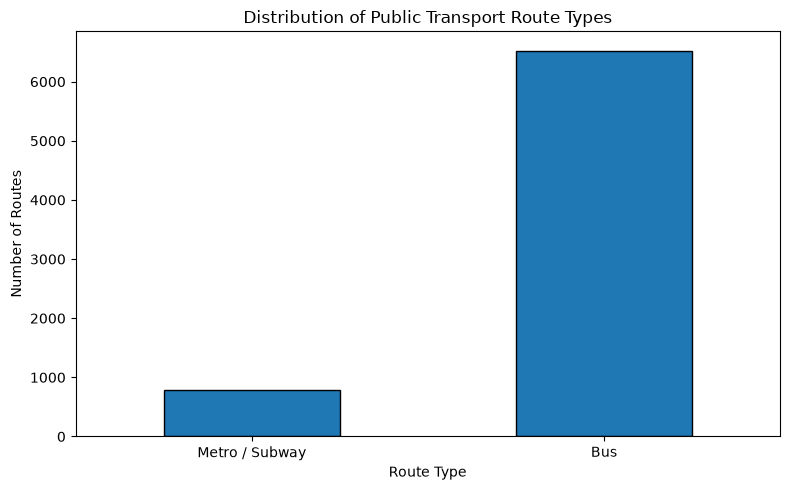

In [14]:
# Step 17 - Route Type Distribution

main_df = datasets["main"].copy()

# Count route types from one-hot encoded columns
route_type_count = pd.Series({
    "Metro / Subway": main_df["categorical__route_type_1"].sum(),
    "Bus": main_df["categorical__route_type_3"].sum()
})

print("Route Type Distribution:")
display(route_type_count)

# Visualization
plt.figure(figsize=(8, 5))

route_type_count.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Distribution of Public Transport Route Types")
plt.xlabel("Route Type")
plt.ylabel("Number of Routes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

K-Means Dataset Columns:
['route_id', 'route_short_name', 'city', 'Cluster']

K-Means Cluster Distribution:


Cluster
0    6525
1     180
2     227
3     380
Name: count, dtype: int64

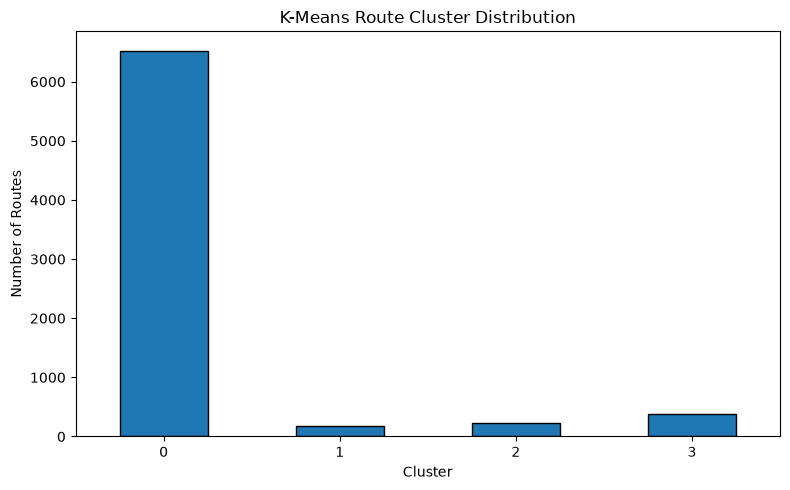

In [15]:

# Step 18 - K-Means Cluster Distribution

# Load K-Means clustering results
kmeans_df = datasets["kmeans"].copy()

# Display available columns
print("K-Means Dataset Columns:")
print(kmeans_df.columns.tolist())

# Identify the cluster column
cluster_column = next(
    (col for col in kmeans_df.columns if "cluster" in col.lower()),
    None
)

if cluster_column is not None:

    # Count routes in each cluster
    kmeans_cluster_count = (
        kmeans_df[cluster_column]
        .value_counts()
        .sort_index()
    )

    print("\nK-Means Cluster Distribution:")
    display(kmeans_cluster_count)

    # Visualize cluster distribution
    plt.figure(figsize=(8, 5))

    kmeans_cluster_count.plot(
        kind="bar",
        edgecolor="black"
    )

    plt.title("K-Means Route Cluster Distribution")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Routes")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

else:
    print("Cluster column not found. Please check the dataset.")

DBSCAN Dataset Columns:
['route_id', 'route_short_name', 'city', 'Cluster']

DBSCAN Cluster Distribution:


Cluster
-1       6
 0    6519
 1     227
 2     180
 3     380
Name: count, dtype: int64

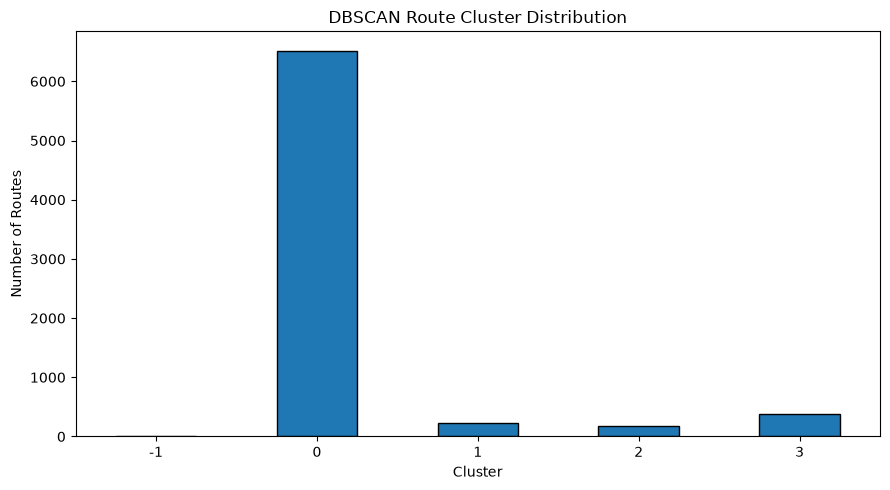

In [16]:
# Step 19 - DBSCAN Cluster Distribution

dbscan_df = datasets["dbscan"].copy()

print("DBSCAN Dataset Columns:")
print(dbscan_df.columns.tolist())

# Identify DBSCAN cluster column
cluster_column = next(
    (col for col in dbscan_df.columns if "cluster" in col.lower()),
    None
)

if cluster_column is not None:

    dbscan_cluster_count = (
        dbscan_df[cluster_column]
        .value_counts()
        .sort_index()
    )

    print("\nDBSCAN Cluster Distribution:")
    display(dbscan_cluster_count)

    # Visualization
    plt.figure(figsize=(9, 5))

    dbscan_cluster_count.plot(
        kind="bar",
        edgecolor="black"
    )

    plt.title("DBSCAN Route Cluster Distribution")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Routes")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

else:
    print("DBSCAN cluster column not found.")

K-Means vs DBSCAN Comparison:


,K-Means,DBSCAN
Cluster,,
-1,0,6
0,6525,6519
1,180,227
2,227,180
3,380,380


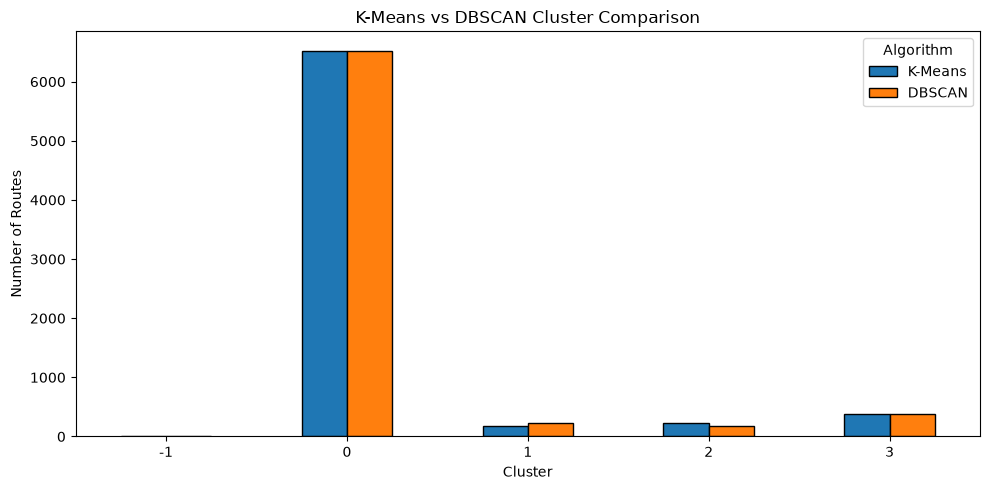

In [17]:
# Step 20 - K-Means vs DBSCAN Comparison

kmeans_counts = (
    datasets["kmeans"]["Cluster"]
    .value_counts()
    .sort_index()
)

dbscan_counts = (
    datasets["dbscan"]["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_comparison = pd.DataFrame({
    "K-Means": kmeans_counts,
    "DBSCAN": dbscan_counts
}).fillna(0).astype(int)

print("K-Means vs DBSCAN Comparison:")
display(cluster_comparison)

# Visualization
cluster_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    edgecolor="black"
)

plt.title("K-Means vs DBSCAN Cluster Comparison")
plt.xlabel("Cluster")
plt.ylabel("Number of Routes")
plt.xticks(rotation=0)
plt.legend(title="Algorithm")
plt.tight_layout()
plt.show()


Classification Dataset Columns:
['route_id', 'route_short_name', 'city', 'route_type', 'RF_Predicted_Route_Type', 'XGB_Predicted_Route_Type']

Classification Prediction Distribution:


RF_Predicted_Route_Type
3    3928
1     793
Name: count, dtype: int64

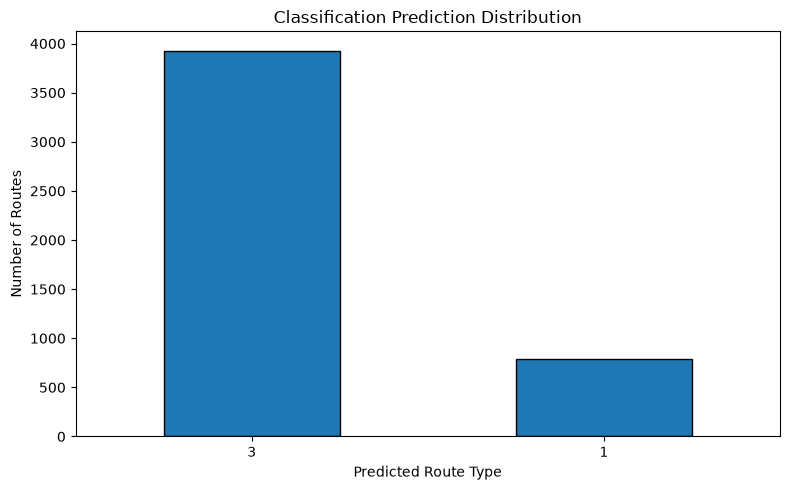

In [18]:
# Step 21 - Classification Prediction Distribution

classification_df = datasets["classification"].copy()

print("Classification Dataset Columns:")
print(classification_df.columns.tolist())

# Display prediction distribution
print("\nClassification Prediction Distribution:")

prediction_column = next(
    (
        col for col in classification_df.columns
        if "prediction" in col.lower()
        or "predicted" in col.lower()
    ),
    None
)

if prediction_column is not None:

    prediction_count = (
        classification_df[prediction_column]
        .value_counts()
    )

    display(prediction_count)

    # Visualization
    plt.figure(figsize=(8, 5))

    prediction_count.plot(
        kind="bar",
        edgecolor="black"
    )

    plt.title("Classification Prediction Distribution")
    plt.xlabel("Predicted Route Type")
    plt.ylabel("Number of Routes")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

else:
    print("Prediction column not found. Check the column names.")

XGBoost Prediction Distribution:


XGB_Predicted_Route_Type
1     798
3    3923
Name: count, dtype: int64

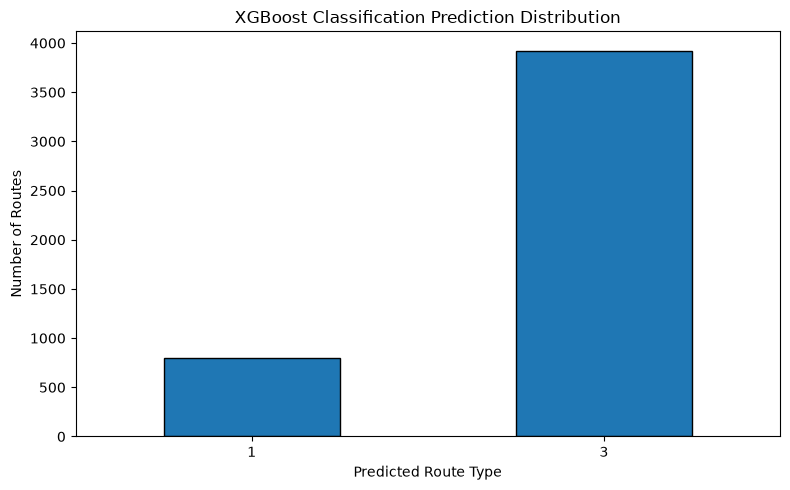

In [19]:
# Step 22 - XGBoost Prediction Distribution

classification_df = datasets["classification"].copy()

# Count XGBoost predictions
xgb_prediction_count = (
    classification_df["XGB_Predicted_Route_Type"]
    .value_counts()
    .sort_index()
)

print("XGBoost Prediction Distribution:")
display(xgb_prediction_count)

# Visualization
plt.figure(figsize=(8, 5))

xgb_prediction_count.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("XGBoost Classification Prediction Distribution")
plt.xlabel("Predicted Route Type")
plt.ylabel("Number of Routes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Random Forest vs XGBoost Prediction Comparison:


,Random Forest,XGBoost
1,793,798
3,3928,3923


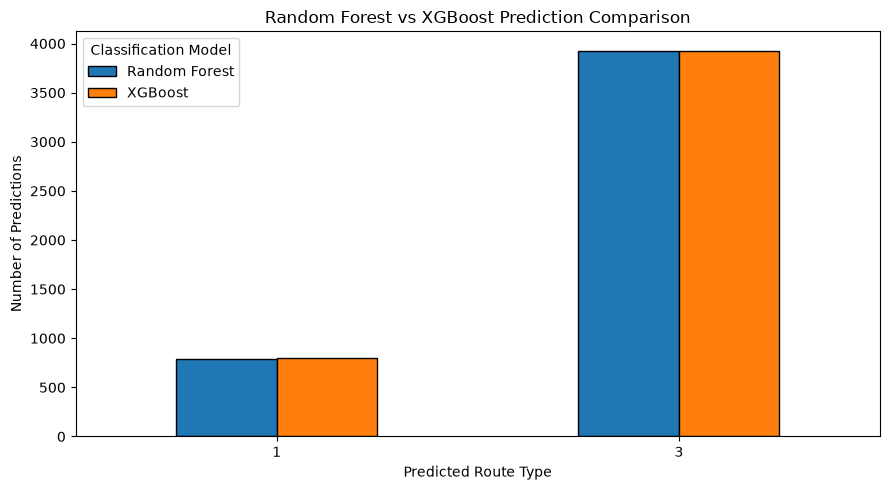

In [20]:
# Step 23 - Random Forest vs XGBoost Comparison

classification_comparison = pd.DataFrame({
    "Random Forest": (
        classification_df["RF_Predicted_Route_Type"]
        .value_counts()
    ),
    "XGBoost": (
        classification_df["XGB_Predicted_Route_Type"]
        .value_counts()
    )
}).fillna(0).astype(int)

classification_comparison = classification_comparison.sort_index()

print("Random Forest vs XGBoost Prediction Comparison:")
display(classification_comparison)

# Visualization
classification_comparison.plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black"
)

plt.title("Random Forest vs XGBoost Prediction Comparison")
plt.xlabel("Predicted Route Type")
plt.ylabel("Number of Predictions")
plt.xticks(rotation=0)
plt.legend(title="Classification Model")
plt.tight_layout()
plt.show()

In [21]:
# Step 24 - Hypothetical Schedule Scenario Analysis

simulation_df = datasets["simulation"].copy()

print("Simulation Dataset Columns:")
print(simulation_df.columns.tolist())

print("\nFirst Five Records:")
display(simulation_df.head())


Simulation Dataset Columns:
['route_id', 'route_short_name', 'city', 'scheduled_trip_count', 'stop_count', 'estimated_straight_line_route_km', 'operating_day_count', 'start_service_hour', 'end_service_hour', 'operates_monday', 'operates_tuesday', 'operates_wednesday', 'operates_thursday', 'operates_friday', 'operates_saturday', 'operates_sunday', 'Original_Trip_Count', 'Scenario_Action']

First Five Records:


,route_id,route_short_name,city,scheduled_trip_count,stop_count,estimated_straight_line_route_km,operating_day_count,start_service_hour,end_service_hour,operates_monday,operates_tuesday,operates_wednesday,operates_thursday,operates_friday,operates_saturday,operates_sunday,Original_Trip_Count,Scenario_Action
0,101sh,101sh,ahmedabad,10,44,44.528570,7,6.0,19.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,10,No Change
1,103-1,103,ahmedabad,22,80,22.365598,7,6.0,21.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,22,No Change
2,103-2,103,ahmedabad,14,52,14.922204,7,5.0,23.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,14,No Change
3,103-3,103,ahmedabad,6,28,8.947943,7,12.0,22.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,6,No Change
4,105,105,ahmedabad,216,40,63.726733,7,5.0,23.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,216,No Change


In [22]:
# Step 24 - Hypothetical Schedule Scenario Analysis

simulation_df = datasets["simulation"].copy()

# Calculate original and simulated trip totals
original_trips = simulation_df["Original_Trip_Count"].sum()
simulated_trips = simulation_df["scheduled_trip_count"].sum()

# Calculate trip difference
trip_difference = simulated_trips - original_trips

# Calculate percentage change
percentage_change = (
    (trip_difference / original_trips) * 100
    if original_trips != 0 else 0
)

# Display results
scenario_summary = pd.DataFrame({
    "Metric": [
        "Original Scheduled Trips",
        "Simulated Scheduled Trips",
        "Difference in Trips",
        "Percentage Change"
    ],
    "Value": [
        original_trips,
        simulated_trips,
        trip_difference,
        round(percentage_change, 2)
    ]
})

print("Hypothetical Schedule Scenario Summary:")
display(scenario_summary)

# Scenario action distribution
print("\nScenario Action Distribution:")

action_count = simulation_df["Scenario_Action"].value_counts()
display(action_count)

Hypothetical Schedule Scenario Summary:


,Metric,Value
0,Original Scheduled Trips,216854.00
1,Simulated Scheduled Trips,216514.00
2,Difference in Trips,-340.00
3,Percentage Change,-0.16



Scenario Action Distribution:


Scenario_Action
No Change                          7306
Hypothetical 10% trip reduction       6
Name: count, dtype: int64

Original vs Simulated Scheduled Trips:


Original Trips     216854
Simulated Trips    216514
dtype: int64

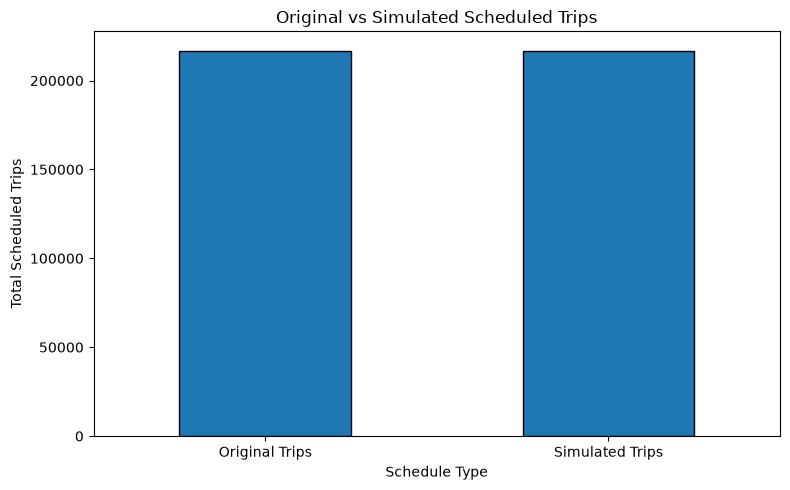

In [23]:
# Step 25 - Original vs Simulated Trips Visualization

trip_comparison = pd.Series({
    "Original Trips": original_trips,
    "Simulated Trips": simulated_trips
})

print("Original vs Simulated Scheduled Trips:")
display(trip_comparison)

# Visualization
plt.figure(figsize=(8, 5))

trip_comparison.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Original vs Simulated Scheduled Trips")
plt.xlabel("Schedule Type")
plt.ylabel("Total Scheduled Trips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Scenario Action Distribution:


Scenario_Action
No Change                          7306
Hypothetical 10% trip reduction       6
Name: count, dtype: int64

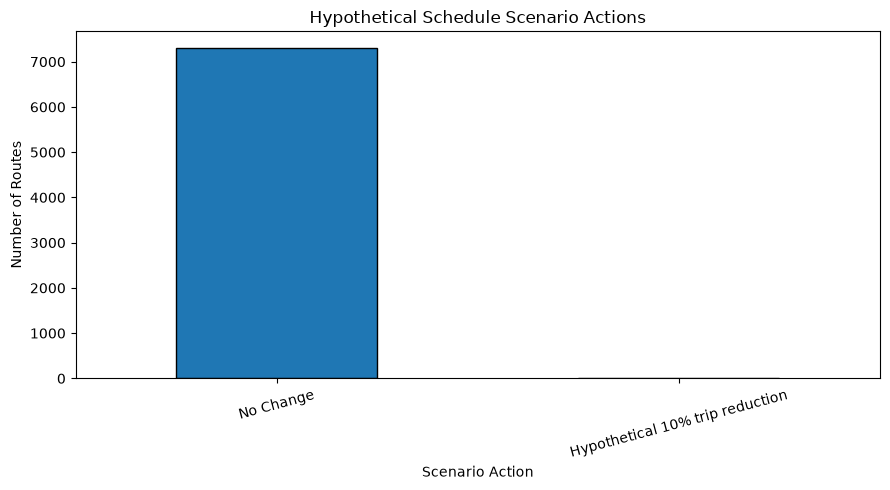

In [24]:
# Step 26 - Scenario Action Distribution

action_count = simulation_df["Scenario_Action"].value_counts()

print("Scenario Action Distribution:")
display(action_count)

# Visualization
plt.figure(figsize=(9, 5))

action_count.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Hypothetical Schedule Scenario Actions")
plt.xlabel("Scenario Action")
plt.ylabel("Number of Routes")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [25]:
# Step 27 - Simulation Comparison Summary

comparison_df = datasets["comparison"].copy()

print("Simulation Comparison Report:")
display(comparison_df)

print("\nComparison Report Columns:")
print(comparison_df.columns.tolist())

Simulation Comparison Report:


,Metric,Before,After,Difference
0,Route Count,7312.000000,7312.000000,0.0
1,Scheduled Trips,216854.000000,216514.000000,-340.0
2,Stop Count (route-level sum),259447.000000,259447.000000,0.0
3,Estimated Distance (km),157563.962635,157563.962635,0.0
4,Operating Days (route-level sum),49874.000000,49874.000000,0.0



Comparison Report Columns:
['Metric', 'Before', 'After', 'Difference']


Scheduled Trips Before and After Optimization:


Before Optimization    216854.0
After Optimization     216514.0
dtype: float64

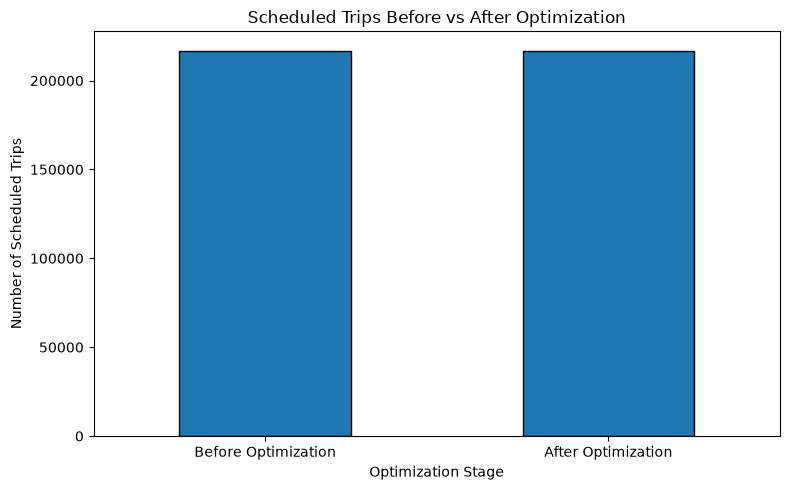

In [26]:
# Step 28 - Before vs After Comparison Chart

comparison_df = datasets["comparison"].copy()

# Select scheduled trips information
trip_row = comparison_df[
    comparison_df["Metric"] == "Scheduled Trips"
]

before_after = pd.Series({
    "Before Optimization": trip_row["Before"].iloc[0],
    "After Optimization": trip_row["After"].iloc[0]
})

print("Scheduled Trips Before and After Optimization:")
display(before_after)

# Visualization
plt.figure(figsize=(8, 5))

before_after.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Scheduled Trips Before vs After Optimization")
plt.xlabel("Optimization Stage")
plt.ylabel("Number of Scheduled Trips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

City-wise Scenario Action Distribution:


Scenario_Action,Hypothetical 10% trip reduction,No Change
city,,
ahmedabad,0,633
chennai,3,4718
hyderabad,3,1028
mumbai,0,612
pune,0,315


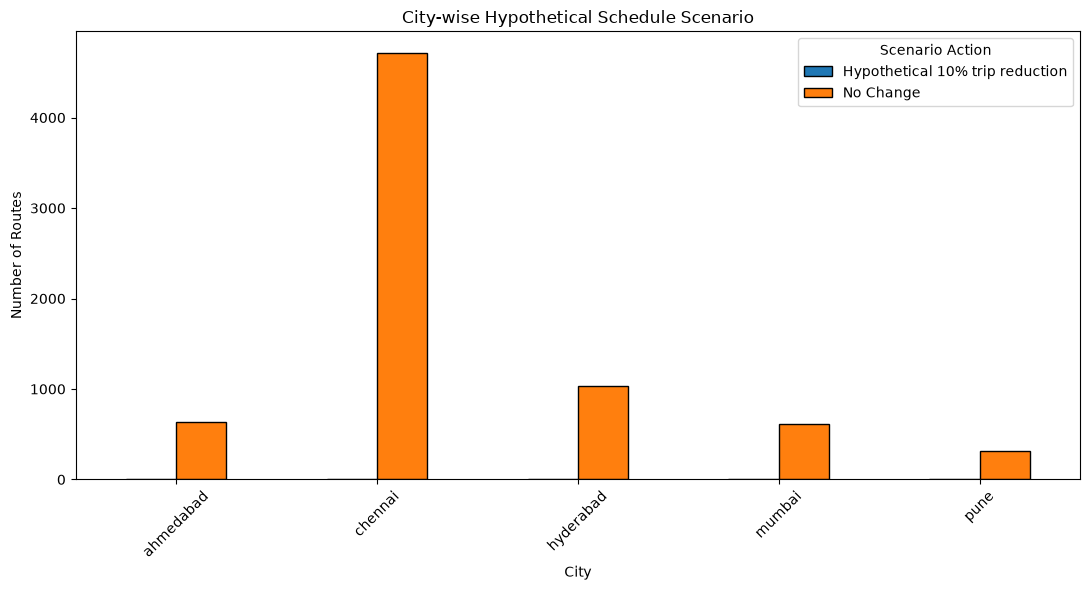

In [27]:
# Step 29 - City-wise Simulation Analysis

city_scenario = (
    simulation_df.groupby(["city", "Scenario_Action"])
    .size()
    .unstack(fill_value=0)
)

print("City-wise Scenario Action Distribution:")
display(city_scenario)

# Visualization
city_scenario.plot(
    kind="bar",
    figsize=(11, 6),
    edgecolor="black"
)

plt.title("City-wise Hypothetical Schedule Scenario")
plt.xlabel("City")
plt.ylabel("Number of Routes")
plt.xticks(rotation=45)
plt.legend(title="Scenario Action")
plt.tight_layout()
plt.show()

In [28]:
# Step 30 - Selected Routes for Hypothetical Scenario

selected_routes = simulation_df[
    simulation_df["Scenario_Action"] != "No Change"
].copy()

selected_routes["Actual_Trip_Change"] = (
    selected_routes["scheduled_trip_count"]
    - selected_routes["Original_Trip_Count"]
)

display(
    selected_routes[
        [
            "city",
            "route_id",
            "route_short_name",
            "Original_Trip_Count",
            "scheduled_trip_count",
            "Actual_Trip_Change",
            "Scenario_Action"
        ]
    ]
)

print("Total selected routes:", len(selected_routes))
print(
    "Routes with reduced trips:",
    (selected_routes["Actual_Trip_Change"] < 0).sum()
)

,city,route_id,route_short_name,Original_Trip_Count,scheduled_trip_count,Actual_Trip_Change,Scenario_Action
1449,chennai,MTC-11347,45A,4,4,0,Hypothetical 10% trip reduction
2508,chennai,MTC-13118,M18C,2,2,0,Hypothetical 10% trip reduction
2522,chennai,MTC-13124,M18C,2,2,0,Hypothetical 10% trip reduction
5729,hyderabad,219,Unknown,2087,1878,-209,Hypothetical 10% trip reduction
6011,hyderabad,300,Unknown,1314,1183,-131,Hypothetical 10% trip reduction
6192,hyderabad,546,Unknown,4,4,0,Hypothetical 10% trip reduction


Total selected routes: 6
Routes with reduced trips: 2


In [29]:
# Step 31 - Routes with Actual Trip Reduction

reduced_routes = simulation_df[
    simulation_df["scheduled_trip_count"] <
    simulation_df["Original_Trip_Count"]
].copy()

print("Routes with Actual Trip Reduction:")
display(
    reduced_routes[
        [
            "city",
            "route_id",
            "route_short_name",
            "Original_Trip_Count",
            "scheduled_trip_count",
            "Scenario_Action"
        ]
    ]
)

print("Total routes with actual reduction:", len(reduced_routes))

Routes with Actual Trip Reduction:


,city,route_id,route_short_name,Original_Trip_Count,scheduled_trip_count,Scenario_Action
5729,hyderabad,219,Unknown,2087,1878,Hypothetical 10% trip reduction
6011,hyderabad,300,Unknown,1314,1183,Hypothetical 10% trip reduction


Total routes with actual reduction: 2


In [30]:
# Step 32 - City-wise Scheduled Trips Before and After Simulation

city_trip_comparison = simulation_df.groupby("city").agg(
    Original_Trips=("Original_Trip_Count", "sum"),
    Simulated_Trips=("scheduled_trip_count", "sum")
)

city_trip_comparison["Trip_Reduction"] = (
    city_trip_comparison["Original_Trips"] -
    city_trip_comparison["Simulated_Trips"]
)

print("City-wise Scheduled Trip Comparison:")
display(city_trip_comparison)

City-wise Scheduled Trip Comparison:


,Original_Trips,Simulated_Trips,Trip_Reduction
city,,,
ahmedabad,14323,14323,0
chennai,48431,48431,0
hyderabad,44892,44552,340
mumbai,99080,99080,0
pune,10128,10128,0


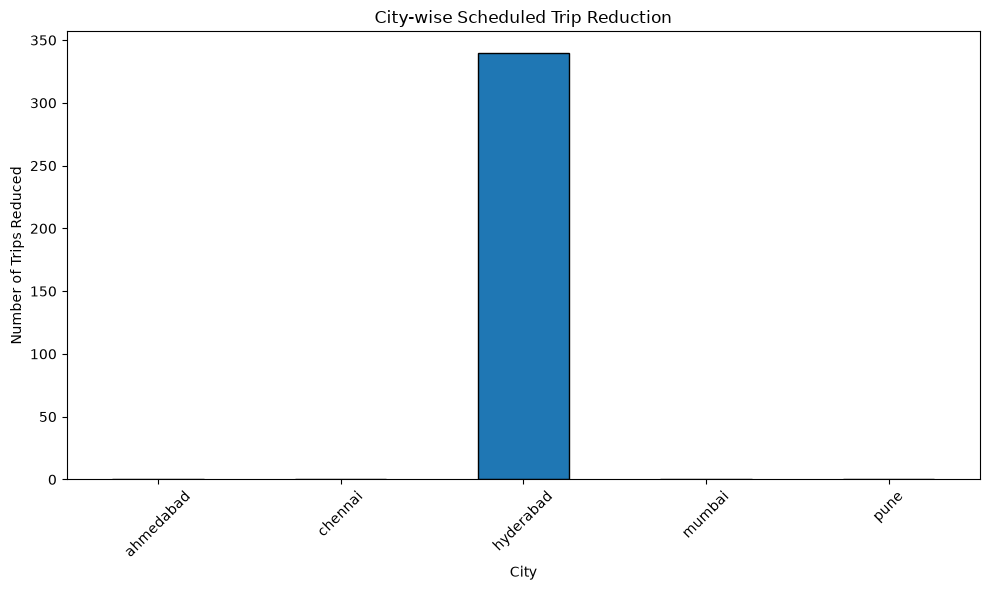

In [31]:
# Step 33 - City-wise Trip Reduction Visualization

city_trip_comparison["Trip_Reduction"].plot(
    kind="bar",
    figsize=(10, 6),
    edgecolor="black"
)

plt.title("City-wise Scheduled Trip Reduction")
plt.xlabel("City")
plt.ylabel("Number of Trips Reduced")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
# Step 34 - City-wise Trip Reduction Percentage

city_trip_comparison["Reduction_Percentage"] = (
    city_trip_comparison["Trip_Reduction"] /
    city_trip_comparison["Original_Trips"]
) * 100

print("City-wise Trip Reduction Percentage:")
display(city_trip_comparison)

City-wise Trip Reduction Percentage:


,Original_Trips,Simulated_Trips,Trip_Reduction,Reduction_Percentage
city,,,,
ahmedabad,14323,14323,0,0.000000
chennai,48431,48431,0,0.000000
hyderabad,44892,44552,340,0.757373
mumbai,99080,99080,0,0.000000
pune,10128,10128,0,0.000000


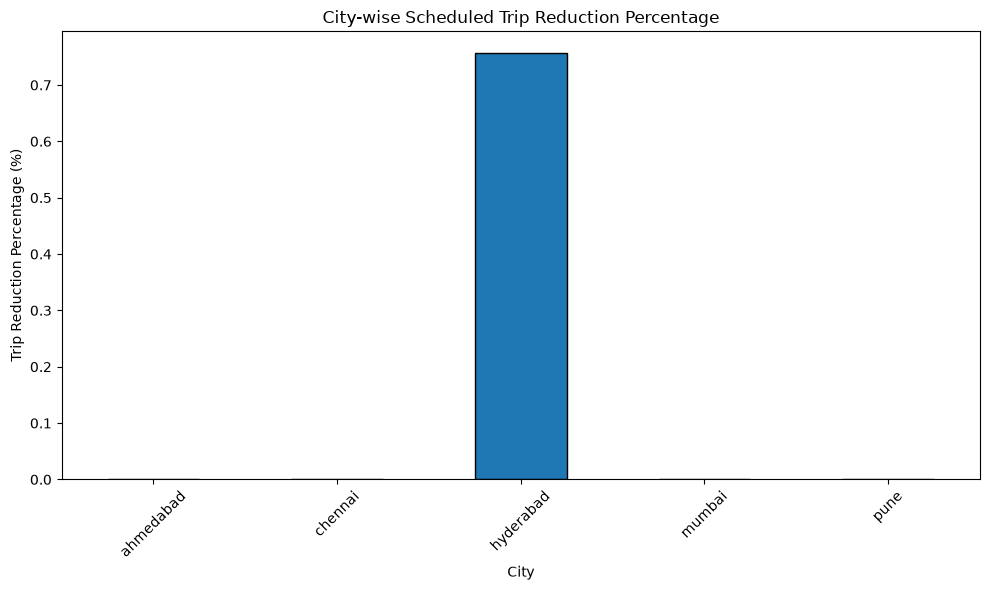

In [33]:
# Step 35 - City-wise Trip Reduction Percentage Visualization

city_trip_comparison["Reduction_Percentage"].plot(
    kind="bar",
    figsize=(10, 6),
    edgecolor="black"
)

plt.title("City-wise Scheduled Trip Reduction Percentage")
plt.xlabel("City")
plt.ylabel("Trip Reduction Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

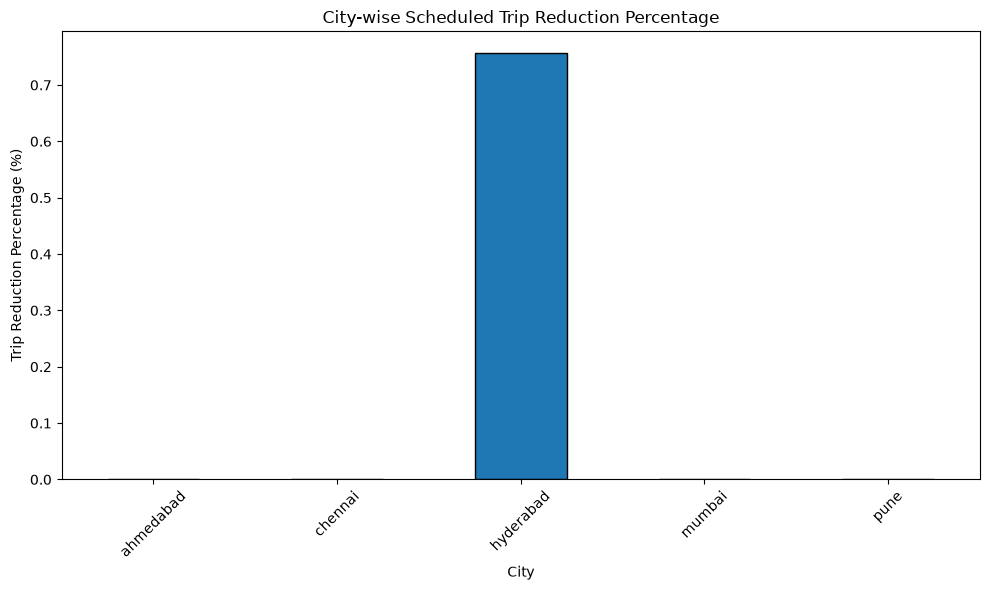

In [35]:
# Step 35 - City-wise Trip Reduction Percentage Visualization

city_trip_comparison["Reduction_Percentage"].plot(
    kind="bar",
    figsize=(10, 6),
    edgecolor="black"
)

plt.title("City-wise Scheduled Trip Reduction Percentage")
plt.xlabel("City")
plt.ylabel("Trip Reduction Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
# Step 36 - Dashboard KPI Summary

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Routes",
        "Total Cities",
        "Total Scheduled Trips",
        "Average Trips per Route",
        "K-Means Clusters",
        "DBSCAN Clusters (excluding noise)",
        "Actual Routes with Trip Reduction",
        "Total Trips Reduced"
    ],
    "Value": [
        len(route_df),
        route_df["city"].nunique(),
        int(simulation_df["Original_Trip_Count"].sum()),
        round(route_df["scheduled_trip_count"].mean(), 2),
        datasets["kmeans"]["Cluster"].nunique(),
        datasets["dbscan"].loc[
            datasets["dbscan"]["Cluster"] != -1, "Cluster"
        ].nunique(),
        len(reduced_routes),
        int(reduced_routes["Original_Trip_Count"].sum() -
            reduced_routes["scheduled_trip_count"].sum())
    ]
})

print("RouteRanker Dashboard KPI Summary:")
display(kpi_summary)


RouteRanker Dashboard KPI Summary:


,KPI,Value
0,Total Routes,7312.00
1,Total Cities,5.00
2,Total Scheduled Trips,216854.00
3,Average Trips per Route,29.66
4,K-Means Clusters,4.00
5,DBSCAN Clusters (excluding noise),4.00
6,Actual Routes with Trip Reduction,2.00
7,Total Trips Reduced,340.00


In [37]:
# Step 37 - Save Dashboard KPI Summary

kpi_output_path = OUTPUT_DIR / "dashboard_kpi_summary.csv"

kpi_summary.to_csv(kpi_output_path, index=False)

print("KPI Summary saved successfully!")
print("Saved location:", kpi_output_path)


KPI Summary saved successfully!
Saved location: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\dashboard\outputs\dashboard_kpi_summary.csv


In [38]:
# Step 38 - Verify Saved KPI Summary

saved_kpi = pd.read_csv(kpi_output_path)

print("Saved KPI File Verification")
print("-" * 40)

display(saved_kpi)

print("Total KPI records:", len(saved_kpi))
print("File exists:", kpi_output_path.exists())

Saved KPI File Verification
----------------------------------------


,KPI,Value
0,Total Routes,7312.00
1,Total Cities,5.00
2,Total Scheduled Trips,216854.00
3,Average Trips per Route,29.66
4,K-Means Clusters,4.00
5,DBSCAN Clusters (excluding noise),4.00
6,Actual Routes with Trip Reduction,2.00
7,Total Trips Reduced,340.00


Total KPI records: 8
File exists: True


In [39]:
# Step 39 - Save City-wise Analysis

city_output_path = OUTPUT_DIR / "city_wise_trip_analysis.csv"

city_trip_comparison.to_csv(city_output_path)

print("City-wise Analysis saved successfully!")
print("Saved location:", city_output_path)




City-wise Analysis saved successfully!
Saved location: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\dashboard\outputs\city_wise_trip_analysis.csv


In [40]:
# Step 40 - Verify Saved City-wise Analysis

saved_city_analysis = pd.read_csv(city_output_path)

print("City-wise Analysis File Verification")
print("-" * 45)

display(saved_city_analysis)

print("Total city records:", len(saved_city_analysis))
print("File exists:", city_output_path.exists())

City-wise Analysis File Verification
---------------------------------------------


,city,Original_Trips,Simulated_Trips,Trip_Reduction,Reduction_Percentage
0,ahmedabad,14323,14323,0,0.000000
1,chennai,48431,48431,0,0.000000
2,hyderabad,44892,44552,340,0.757373
3,mumbai,99080,99080,0,0.000000
4,pune,10128,10128,0,0.000000


Total city records: 5
File exists: True


In [41]:
# Step 41 - Save Actual Reduced Routes

reduced_routes_output_path = (
    OUTPUT_DIR / "actual_reduced_routes.csv"
)

reduced_routes.to_csv(
    reduced_routes_output_path,
    index=False
)

print("Actual Reduced Routes saved successfully!")
print("Saved location:", reduced_routes_output_path)
print("Total reduced routes:", len(reduced_routes))

Actual Reduced Routes saved successfully!
Saved location: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\dashboard\outputs\actual_reduced_routes.csv
Total reduced routes: 2


In [42]:
# Step 42 - Verify Saved Actual Reduced Routes

saved_reduced_routes = pd.read_csv(
    reduced_routes_output_path
)

print("Actual Reduced Routes Verification")
print("-" * 45)

display(saved_reduced_routes)

print("Total records:", len(saved_reduced_routes))
print("File exists:", reduced_routes_output_path.exists())


Actual Reduced Routes Verification
---------------------------------------------


,route_id,route_short_name,city,scheduled_trip_count,stop_count,estimated_straight_line_route_km,operating_day_count,start_service_hour,end_service_hour,operates_monday,operates_tuesday,operates_wednesday,operates_thursday,operates_friday,operates_saturday,operates_sunday,Original_Trip_Count,Scenario_Action
0,219,Unknown,hyderabad,1878,795,29.926609,7,3.0,71.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2087,Hypothetical 10% trip reduction
1,300,Unknown,hyderabad,1183,496,30.923426,7,3.0,311.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1314,Hypothetical 10% trip reduction


Total records: 2
File exists: True


In [43]:
# Step 43 - Module 7 Output Summary

output_files = [
    "dashboard_kpi_summary.csv",
    "city_wise_trip_analysis.csv",
    "actual_reduced_routes.csv"
]

print("MODULE 7 - OUTPUT FILE SUMMARY")
print("=" * 45)

for file_name in output_files:
    file_path = OUTPUT_DIR / file_name

    print(f"File: {file_name}")
    print(f"Exists: {file_path.exists()}")

print("=" * 45)
print("Total output files:", len(output_files))

MODULE 7 - OUTPUT FILE SUMMARY
File: dashboard_kpi_summary.csv
Exists: True
File: city_wise_trip_analysis.csv
Exists: True
File: actual_reduced_routes.csv
Exists: True
Total output files: 3


In [44]:
# Step 44 - Final Module 7 Progress Check

print("=" * 55)
print("ROUTERANKER - MODULE 7 PROGRESS REPORT")
print("=" * 55)

print("\nDATASETS")
print("Datasets loaded:", len(datasets))
print("Total routes:", len(route_df))
print("Total cities:", route_df["city"].nunique())

print("\nANALYSIS")
print("K-Means clusters:", datasets["kmeans"]["Cluster"].nunique())
print("DBSCAN clusters:", datasets["dbscan"].loc[
    datasets["dbscan"]["Cluster"] != -1, "Cluster"
].nunique())

print("\nSIMULATION")
print("Actual reduced routes:", len(reduced_routes))
print("Total trips reduced:", int(
    reduced_routes["Original_Trip_Count"].sum()
    - reduced_routes["scheduled_trip_count"].sum()
))

print("\nOUTPUT FILES")
print("KPI summary:", (OUTPUT_DIR / "dashboard_kpi_summary.csv").exists())
print("City analysis:", (OUTPUT_DIR / "city_wise_trip_analysis.csv").exists())
print("Reduced routes:", (OUTPUT_DIR / "actual_reduced_routes.csv").exists())

print("\n" + "=" * 55)
print("MODULE 7 ANALYSIS AND OUTPUT PREPARATION CHECK COMPLETED")
print("=" * 55)

ROUTERANKER - MODULE 7 PROGRESS REPORT

DATASETS
Datasets loaded: 9
Total routes: 7312
Total cities: 5

ANALYSIS
K-Means clusters: 4
DBSCAN clusters: 4

SIMULATION
Actual reduced routes: 2
Total trips reduced: 340

OUTPUT FILES
KPI summary: True
City analysis: True
Reduced routes: True

MODULE 7 ANALYSIS AND OUTPUT PREPARATION CHECK COMPLETED


In [45]:
# Step 45 - Check Existing Dashboard Files

DASHBOARD_DIR = PROJECT_DIR / "dashboard"

print("EXISTING DASHBOARD STRUCTURE")
print("=" * 45)

for item in sorted(DASHBOARD_DIR.rglob("*")):
    if item.is_file():
        print(item.relative_to(PROJECT_DIR))

print("=" * 45)

EXISTING DASHBOARD STRUCTURE
dashboard\modules\__init__.py
dashboard\modules\__pycache__\__init__.cpython-314.pyc
dashboard\modules\__pycache__\data_loader.cpython-314.pyc
dashboard\modules\data_loader.py
dashboard\modules\data_validation.py
dashboard\outputs\actual_reduced_routes.csv
dashboard\outputs\city_wise_trip_analysis.csv
dashboard\outputs\dashboard_kpi_summary.csv
